# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

Ответ: Обучал модель на NVIDIA GeForce RTX 5070 под Windows, Python 3.14.7. Взял YOLO26n из ultralytics 8.4.182 и [BCCD](https://github.com/Shenggan/BCCD_Dataset), небольшой датасет из 364 изображений клеток крови с лицензией [MIT](https://github.com/Shenggan/BCCD_Dataset/blob/master/LICENSE).

Пользовался шаблоном задания, [описанием YOLO26](https://docs.ultralytics.com/models/yolo26/), [документацией по обучению](https://docs.ultralytics.com/modes/train/), [кодом Detect](https://github.com/ultralytics/ultralytics/blob/v8.4.182/ultralytics/nn/modules/head.py) и [описанием лицензии Ultralytics](https://www.ultralytics.com/license).

Для дополнительных снимков использовал [PBC](https://data.mendeley.com/datasets/snkd93bnjr/1) с лицензией CC BY 4.0 и [зеркало MicroBench](https://huggingface.co/datasets/nirschl-lab/acevedo_et_al_2020). Для сравнения моделей и экспорта пользовался документацией [RT-DETR](https://docs.ultralytics.com/models/rtdetr/) и [ONNX](https://docs.ultralytics.com/modes/export/).

In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    installed = importlib.metadata.version('ultralytics')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '8.4.182' or any(importlib.util.find_spec(name) is None for name in ('polars', 'thop', 'ultralytics_platform')):
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'ultralytics==8.4.182'], check=True)

import csv
import hashlib
import io
import json
import math
import os
import random
import shutil
import time
import urllib.request
import xml.etree.ElementTree as ET
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance, ImageFilter
from scipy import ndimage
import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO
from IPython.display import display

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('jpeg')
torch.set_num_threads(8)
DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.182, torch 2.11.0+cu130, device: NVIDIA GeForce RTX 5070


In [2]:
FAST_MODE = False
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}
SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64
WORKERS = 0 if os.name == 'nt' else 2
RUN_TIMES = {}
REUSE_COMPLETED_RUNS = True


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=WEIGHTS,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1024 ** 2,
                  params=sum(p.numel() for p in model_coco.model.parameters()),
                  n_classes_coco=len(model_coco.names))
dummy_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
for _ in range(5):
    model_coco.predict(dummy_image, imgsz=IMGSZ, device=DEVICE, verbose=False, end2end=True)
times = []
for _ in range(20):
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    model_coco.predict(dummy_image, imgsz=IMGSZ, device=DEVICE, verbose=False, end2end=True)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    times.append((time.perf_counter() - start) * 1000)
MODEL_INFO['latency_ms'] = float(np.mean(times))
MODEL_INFO['latency_protocol'] = 'batch=1, 640x640, FP32, 5 warmups, 20 runs, predict wall time, CUDA synchronized, end2end=True'

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


... (15 outputs left out)

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.182',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 18.299594999916735,
 'latency_protocol': 'batch=1, 640x640, FP32, 5 warmups, 20 runs, predict wall time, CUDA synchronized, end2end=True'}

Ответ: Я выбрал YOLO26n, потому что она быстро обучается и требует мало памяти. Для небольшого BCCD этого достаточно, чтобы сравнить два варианта обучения на одной видеокарте. В [таблице Ultralytics](https://docs.ultralytics.com/models/yolo26/) у версии n указаны 2.4 млн параметров, mAP50-95 на COCO 40.9 и задержка 1.7 мс на T4 с TensorRT10. У версии s качество выше, 48.6, но она больше и медленнее: 9.5 млн параметров и 2.5 мс. Для ветки end-to-end качество составляет 40.1 и 47.8 соответственно.

В таблице параметры посчитаны после слияния слоев и удаления лишней ветки, а мой код считает их до этих изменений, поэтому числа отличаются. Я измерял время всего predict в PyTorch, поэтому напрямую сравнивать его со временем TensorRT нельзя.

Код и веса доступны по AGPL-3.0. Нужно сохранять сведения об авторстве и лицензию, а при распространении измененной программы предоставлять ее исходный код. Это требование действует и для пользователей, которые работают с измененной программой через сеть. Также есть отдельная коммерческая лицензия, подробнее об этом написано [на сайте Ultralytics](https://www.ultralytics.com/license).

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    count = lambda modules: sum(p.numel() for layer in modules for p in layer.parameters())
    return dict(backbone=count(layers[:n_backbone]), neck=count(layers[n_backbone:-1]),
                head=count(layers[-1:]))


def head_inputs_and_output(det_model, imgsz=640):
    feature_shapes = []
    def capture(module, args):
        feature_shapes.extend(tuple(x.shape) for x in args[0])
    was_training = det_model.training
    handle = det_model.model[-1].register_forward_pre_hook(capture)
    parameter = next(det_model.parameters())
    try:
        det_model.eval()
        det_model.end2end = True
        with torch.inference_mode():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=parameter.device, dtype=parameter.dtype))
    finally:
        handle.remove()
        det_model.train(was_training)
    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))

[(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


Ответ: Backbone выделяет признаки изображения с помощью сверток и блоков C3k2. SPPF помогает учитывать более широкую область изображения, а C2PSA добавляет внимание к признакам. Neck объединяет признаки разных масштабов: крупные карты сохраняют мелкие детали, а маленькие дают больше информации о клетке целиком. Для этого используются увеличение карт, объединение по каналам и свертки с шагом 2.

В Detect приходят три карты с шагами 8, 16 и 32. При входе 640 на 640 их размеры равны 80 на 80, 40 на 40 и 20 на 20, что в сумме дает 8400 позиций. Для каждой позиции модель предсказывает расстояния до четырех сторон рамки и оценки классов. Готовых шаблонов размеров рамок здесь нет, поэтому детектор называется anchor-free. В YOLO26 также убран DFL.

При обучении one2many одному объекту могут соответствовать несколько предсказаний, а в one2one назначается одно. Благодаря one2one модель может работать без NMS, который обычно убирает повторные рамки. В установленной версии по умолчанию выбрана one2many, поэтому я явно включил end2end и отдельно сравнил режимы в бонусе. На backbone приходится около 53 процентов параметров, на neck 35, на head 12.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
DATA_REVISION = 'd272fb14cdff6e473fafeeeba32aba5f560e9e43'
DATA_URL = f'https://codeload.github.com/Shenggan/BCCD_Dataset/zip/{DATA_REVISION}'
DATASET_NAME = f'BCCD, https://github.com/Shenggan/BCCD_Dataset, MIT, revision {DATA_REVISION}'
CLASSES = ['RBC', 'WBC', 'Platelets']
raw_root = DATA_ROOT / 'raw'
bccd_root = raw_root / f'BCCD_Dataset-{DATA_REVISION}' / 'BCCD'
if not bccd_root.exists():
    raw_root.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(DATA_URL, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        archive.extractall(raw_root)

all_records = []
cleaning = Counter(clipped=0, removed=0, duplicate_images=0)
hashes = set()
for annotation in sorted((bccd_root / 'Annotations').glob('*.xml')):
    root = ET.parse(annotation).getroot()
    image = bccd_root / 'JPEGImages' / root.findtext('filename')
    with Image.open(image) as im:
        width, height = im.size
        digest = hashlib.sha256(im.convert('RGB').tobytes()).hexdigest()
    if digest in hashes:
        cleaning['duplicate_images'] += 1
        continue
    hashes.add(digest)
    boxes, labels = [], []
    for obj in root.findall('object'):
        box = obj.find('bndbox')
        original = np.array([float(box.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
        original[:2] -= 1
        clipped = np.clip(original, [0, 0, 0, 0], [width, height, width, height])
        cleaning['clipped'] += int(not np.array_equal(original, clipped))
        if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
            cleaning['removed'] += 1
            continue
        boxes.append(clipped)
        labels.append(CLASSES.index(obj.findtext('name')))
    all_records.append(dict(image=image, width=width, height=height,
                            boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
                            labels=np.array(labels, dtype=np.int64)))
indices = np.random.default_rng(SEED).permutation(len(all_records))
n_train, n_val = int(0.7 * len(indices)), int(0.15 * len(indices))
records = {name: [all_records[i] for i in idx] for name, idx in
           {'train': indices[:n_train], 'val': indices[n_train:n_train + n_val],
            'test': indices[n_train + n_val:]}.items()}
image_sets = [{r['image'].name for r in recs} for recs in records.values()]
assert all(not a & b for i, a in enumerate(image_sets) for b in image_sets[i + 1:])
print('Очистка:', dict(cleaning))
print('Размеры:', {s: len(r) for s, r in records.items()})

Очистка: {'clipped': 0, 'removed': 0, 'duplicate_images': 0}
Размеры: {'train': 254, 'val': 54, 'test': 56}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 254, 'val': 54, 'test': 56}

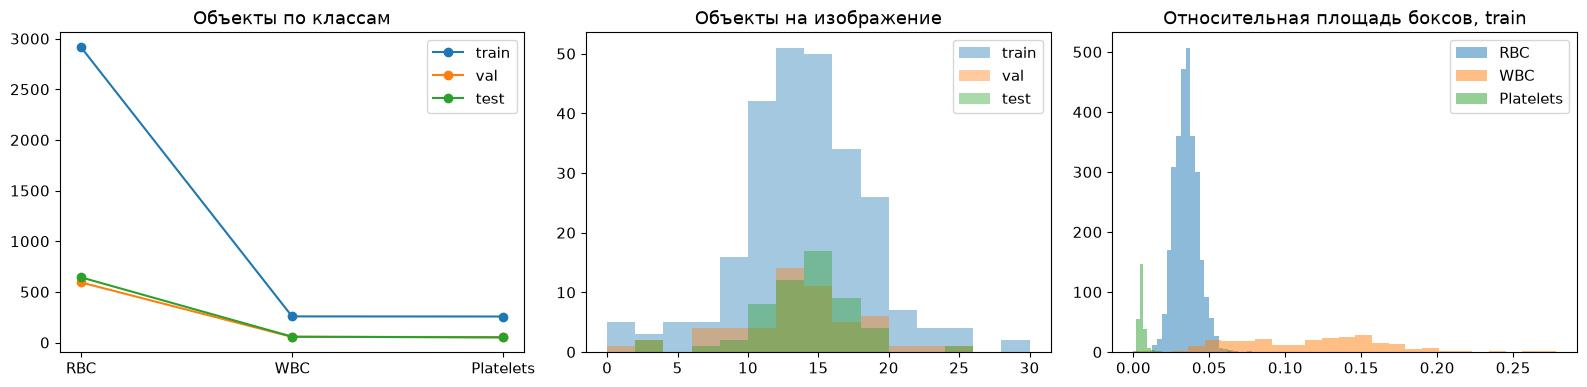

{
  "train": {
    "images": 254,
    "objects_per_class": {
      "RBC": 2917,
      "WBC": 258,
      "Platelets": 257
    },
    "objects_per_image_mean": 13.511811023622048,
    "objects_per_image_max": 30
  },
  "val": {
    "images": 54,
    "objects_per_class": {
      "RBC": 594,
      "WBC": 56,
      "Platelets": 54
    },
    "objects_per_image_mean": 13.037037037037036,
    "objects_per_image_max": 25
  },
  "test": {
    "images": 56,
    "objects_per_class": {
      "RBC": 644,
      "WBC": 58,
      "Platelets": 50
    },
    "objects_per_image_mean": 13.428571428571429,
    "objects_per_image_max": 24
  }
}


In [11]:
DATA_STATS = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for split, recs in records.items():
    counts = Counter(int(c) for r in recs for c in r['labels'])
    objects = np.array([len(r['labels']) for r in recs])
    DATA_STATS[split] = dict(images=len(recs), objects_per_class={n: counts[i] for i, n in enumerate(CLASSES)},
                             objects_per_image_mean=float(objects.mean()), objects_per_image_max=int(objects.max()))
    axes[0].plot(CLASSES, [counts[i] for i in range(len(CLASSES))], 'o-', label=split)
    axes[1].hist(objects, bins=np.arange(0, 32, 2), alpha=0.4, label=split)
for c, name in enumerate(CLASSES):
    sizes = np.array([(b[2] - b[0]) * (b[3] - b[1]) / (r['width'] * r['height'])
                      for r in records['train'] for b, label in zip(r['boxes'], r['labels']) if label == c])
    axes[2].hist(sizes, bins=25, alpha=0.5, label=name)
axes[0].set_title('Объекты по классам')
axes[1].set_title('Объекты на изображение')
axes[2].set_title('Относительная площадь боксов, train')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
print(json.dumps(DATA_STATS, ensure_ascii=False, indent=2))

Ответ: Я взял все 364 изображения BCCD с разметкой VOC XML и лицензией MIT. В датасете три класса: RBC, WBC и Platelets, то есть эритроциты, лейкоциты и тромбоциты. После перемешивания с seed 0 получилось 254 изображения для обучения, 54 для валидации и 56 для теста.

В обучающей части 2917 RBC, 258 WBC и 257 Platelets, поэтому эритроцитов заметно больше остальных клеток. На одном изображении в среднем около 13 объектов, максимум 30. Тромбоциты самые мелкие, а клетки часто перекрываются, что может мешать поиску точных границ.

Проверка не нашла рамок с нулевой площадью, выходов за изображение или точных копий изображений, поэтому удалять или обрезать их не пришлось. На примерах видны широкие рамки и клетки у края без полной разметки. Данных о пациентах нет, поэтому я не могу проверить, попали ли снимки одного пациента в разные части датасета.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    boxes = np.asarray(boxes).reshape(-1, 4)
    lines = []
    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = box
        values = ((x1 + x2) / (2 * width), (y1 + y2) / (2 * height),
                  (x2 - x1) / width, (y2 - y1) / height)
        lines.append(str(int(label)) + ' ' + ' '.join(f'{v:.6f}' for v in values))
    return '\n'.join(lines)


def from_yolo(text, width, height):
    boxes, labels = [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        label, cx, cy, w, h = map(float, line.split())
        boxes.append([(cx - w / 2) * width, (cy - h / 2) * height,
                      (cx + w / 2) * width, (cy + h / 2) * height])
        labels.append(int(label))
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        image_path = Path(r['image'])
        shutil.copy2(image_path, image_dir / image_path.name)
        (label_dir / f'{image_path.stem}.txt').write_text(
            to_yolo(r['boxes'], r['labels'], r['width'], r['height']), encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: C:/Users/Aidors/Documents/Codex/2026-11-22/c-users-aidors-desktop-hw2-students/work/execution/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



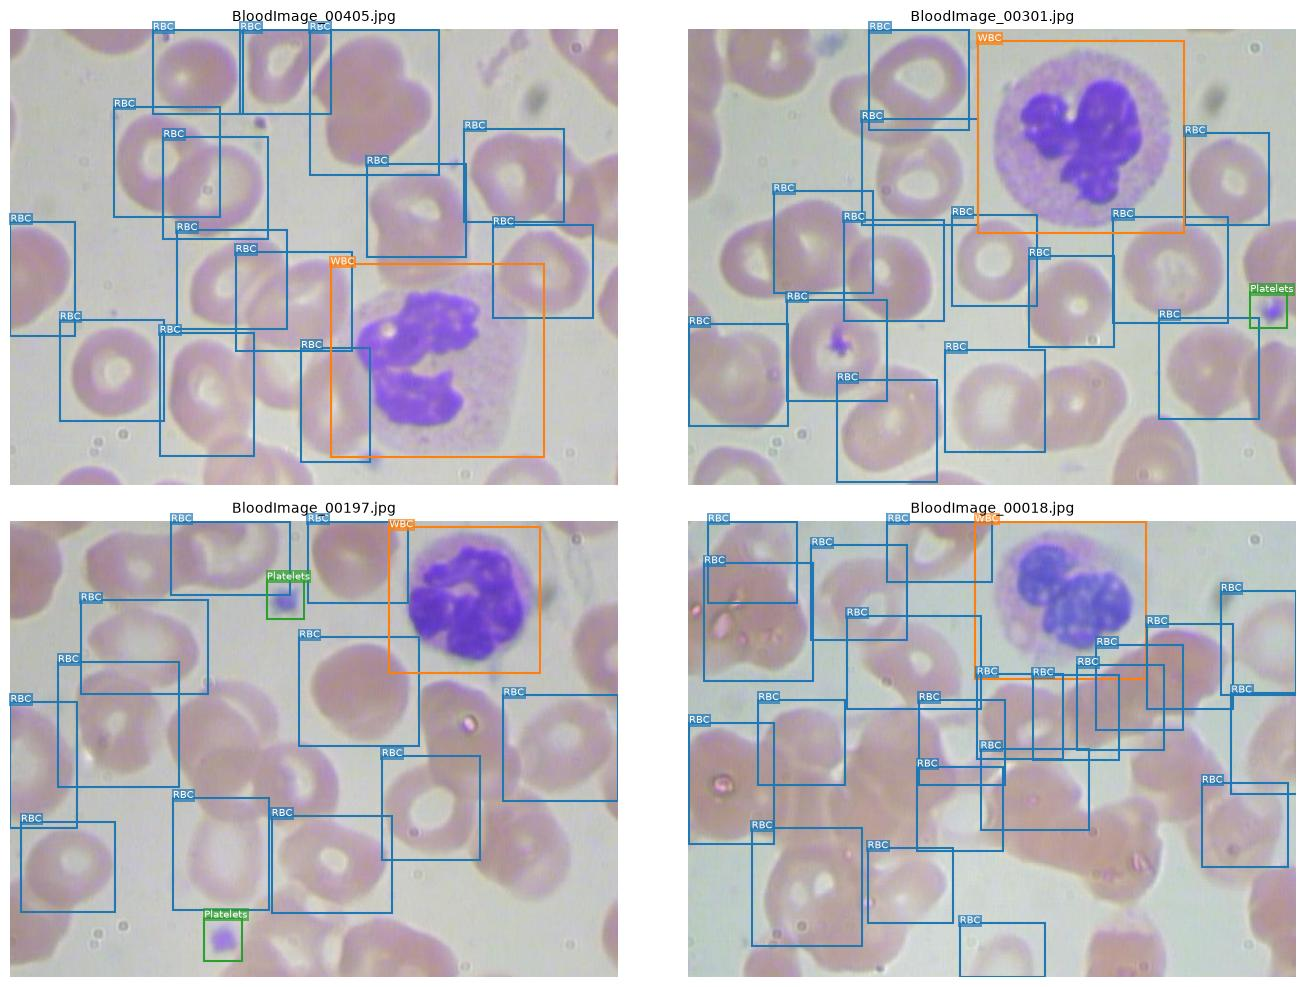

Максимальная ошибка восстановления в пикселях: 0.0003204345703125


In [15]:
max_roundtrip_error = 0.0
for split, recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT / 'labels' / split / f'{Path(r["image"]).stem}.txt').read_text()
        boxes, labels = from_yolo(text, r['width'], r['height'])
        assert np.array_equal(labels, r['labels'])
        assert np.allclose(boxes, r['boxes'], atol=0.002)
        max_roundtrip_error = max(max_roundtrip_error, float(np.max(np.abs(boxes - r['boxes']), initial=0)))
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, r in zip(axes.flat, records['train'][:4]):
    text = (YOLO_ROOT / 'labels/train' / f'{Path(r["image"]).stem}.txt').read_text()
    boxes, labels = from_yolo(text, r['width'], r['height'])
    draw_boxes(ax, Image.open(r['image']), boxes, labels, CLASSES, title=Path(r['image']).name)
plt.tight_layout()
plt.show()
print('Максимальная ошибка восстановления в пикселях:', max_roundtrip_error)

Ответ: Я перевел исходные рамки из VOC XML в YOLO и затем прочитал сохраненные txt обратно. В VOC координаты начинаются с единицы, поэтому у левой и верхней границы вычел единицу. Открытые тесты и проверка всех файлов прошли, разница после округления получилась очень маленькой.

Такая проверка показывает, что две функции согласованы между собой. Но если в обеих есть одна и та же ошибка, тест может ее пропустить, как и неверный класс или пропущенную клетку в исходной разметке. Поэтому я еще посмотрел рамки на изображениях: так проще заметить смещение, перепутанные оси или неправильный размер.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Совпадающие классы: {} mAP50: 0.0


Частые COCO-предсказания: [('donut', 2373), ('apple', 1229), ('orange', 953), ('cake', 901), ('person', 516), ('teddy bear', 282), ('bowl', 156), ('cup', 140), ('carrot', 111), ('vase', 103)]


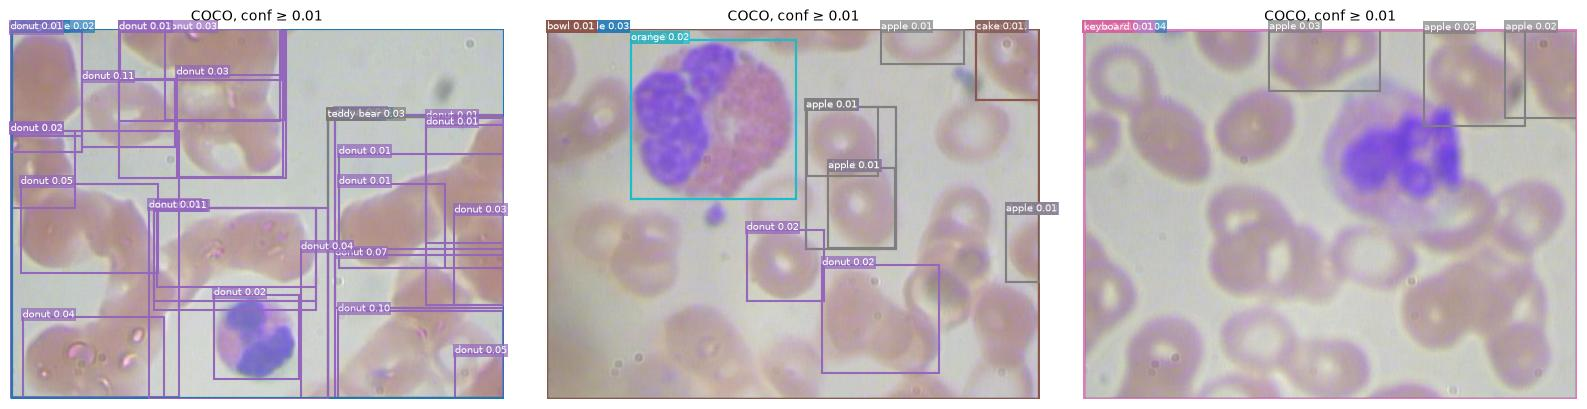

In [16]:
start = time.perf_counter()
coco_predictions = predict_records(model_coco, records[FINAL_SPLIT], end2end=True)
RUN_TIMES['coco_predict'] = time.perf_counter() - start
coco_overlap = {i: CLASSES.index(name) for i, name in model_coco.names.items() if name in CLASSES}
mapped_predictions = []
for pred in coco_predictions:
    keep = np.array([int(label) in coco_overlap for label in pred['labels']], dtype=bool)
    mapped_predictions.append(dict(boxes=pred['boxes'][keep], scores=pred['scores'][keep],
                                   labels=np.array([coco_overlap[int(label)] for label in pred['labels'][keep]], dtype=np.int64)))
coco_map50, coco_aps = evaluate_map50(mapped_predictions, records[FINAL_SPLIT], len(CLASSES))
print('Совпадающие классы:', coco_overlap, 'mAP50:', coco_map50)
print('Частые COCO-предсказания:', Counter(model_coco.names[int(c)] for p in coco_predictions for c in p['labels']).most_common(10))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, r, pred in zip(axes, records[FINAL_SPLIT][:3], coco_predictions[:3]):
    keep = pred['scores'] >= 0.01
    draw_boxes(ax, Image.open(r['image']), pred['boxes'][keep], pred['labels'][keep], model_coco.names,
               pred['scores'][keep], title='COCO, conf ≥ 0.01')
plt.tight_layout()
plt.show()

In [17]:
def heuristic_detect(image_path):
    rgb = np.asarray(Image.open(image_path).convert('RGB'), dtype=float) / 255
    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    purple = (red + blue) / 2 - green
    mask = (purple > HEURISTIC['threshold']) & (green < 0.75)
    mask = ndimage.binary_opening(mask, iterations=1)
    mask = ndimage.binary_closing(mask, iterations=2)
    mask = ndimage.binary_fill_holes(mask)
    components, _ = ndimage.label(mask)
    boxes, scores, labels = [], [], []
    for i, region in enumerate(ndimage.find_objects(components), 1):
        if region is None:
            continue
        yy, xx = region
        area = int(np.sum(components[region] == i))
        if area < HEURISTIC['min_area']:
            continue
        label = 1 if area >= HEURISTIC['wbc_area'] else 2
        pad = HEURISTIC['padding'] if label == 1 else 2
        boxes.append([max(0, xx.start - pad), max(0, yy.start - pad),
                      min(rgb.shape[1], xx.stop + pad), min(rgb.shape[0], yy.stop + pad)])
        scores.append(float(np.clip(purple[region][components[region] == i].mean(), 0, 1)))
        labels.append(label)
    return dict(boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
                scores=np.array(scores), labels=np.array(labels, dtype=np.int64))

In [18]:
train_pixels = []
train_areas = {1: [], 2: []}
for r in records['train']:
    rgb = np.asarray(Image.open(r['image']).convert('RGB'), dtype=float) / 255
    for box, label in zip(r['boxes'], r['labels']):
        if label not in train_areas:
            continue
        x1, y1, x2, y2 = box.astype(int)
        crop = rgb[y1:y2, x1:x2]
        train_pixels.extend((((crop[..., 0] + crop[..., 2]) / 2 - crop[..., 1]).ravel()[::16]).tolist())
        train_areas[int(label)].append((x2 - x1) * (y2 - y1))
HEURISTIC = dict(threshold=float(max(0.08, np.quantile(train_pixels, 0.70))),
                 min_area=float(np.median(train_areas[2]) * 0.05),
                 wbc_area=float(np.sqrt(np.median(train_areas[1]) * np.median(train_areas[2])) * 0.4),
                 padding=int(np.sqrt(np.median(train_areas[1])) * 0.1))
print('Параметры из train:', HEURISTIC)

Параметры из train: {'threshold': 0.18039215686274512, 'min_area': 78.0, 'wbc_area': 3019.9353635467105, 'padding': 19}


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.2816784061781235,
 'heuristic_ap50_per_class': {'RBC': 0.0,
  'WBC': 0.8440828375819895,
  'Platelets': 0.0009523809523809524}}

Ответ: В COCO нет классов клеток крови, поэтому перенести предсказанные классы на BCCD не получилось и mAP50 равен нулю. При этом сама модель что-то находит, но часто называет клетки donut, apple или orange. По виду круглых клеток понятно, откуда могли появиться такие ошибки.

Мой простой алгоритм выделяет фиолетовые участки и по площади разделяет их на WBC и Platelets. Все его пороги рассчитаны по обучающим изображениям. На тесте mAP50 получился 0.2817, AP50 для WBC 0.8441, для Platelets 0.0010, для RBC 0. Алгоритм хорошо находит крупные окрашенные ядра лейкоцитов, но путает маленькие тромбоциты с фрагментами ядер и совсем не ищет эритроциты.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def experiment_signature(weights, args):
    digest = hashlib.sha256(DATA_YAML.read_bytes())
    files = sorted([*YOLO_ROOT.glob('images/*/*'), *YOLO_ROOT.glob('labels/*/*.txt')])
    for path in files:
        digest.update(path.relative_to(YOLO_ROOT).as_posix().encode())
        digest.update(path.read_bytes())
    config = dict(args=args, weights_sha256=hashlib.sha256(Path(weights).read_bytes()).hexdigest(),
                  data_sha256=digest.hexdigest())
    return hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()


def train_yolo(name, weights=WEIGHTS, **args):
    run_path = RUNS.resolve() / name
    signature = experiment_signature(weights, args)
    marker = run_path / 'completed.json'
    if REUSE_COMPLETED_RUNS and marker.exists() and (run_path / 'weights/best.pt').exists():
        completed = json.loads(marker.read_text())
        if completed['signature'] == signature:
            print(f'Используется завершенное обучение {name}, число эпох: {completed["epochs"]}')
            return YOLO(run_path / 'weights/best.pt'), completed['seconds'], run_path
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    seconds = time.perf_counter() - start
    run_path = Path(model.trainer.save_dir)
    with (run_path / 'results.csv').open(newline='') as stream:
        epochs = len(list(csv.DictReader(stream)))
    marker = run_path / 'completed.json'
    marker.write_text(json.dumps(dict(signature=signature, seconds=seconds, epochs=epochs)), encoding='utf-8')
    return model, seconds, run_path


def read_results(run_dir):
    with open(Path(run_dir) / 'results.csv', newline='') as stream:
        rows = list(csv.DictReader(stream))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW', lr0=0.001,
                  lrf=0.05, weight_decay=0.0005, warmup_epochs=3, patience=20,
                  mosaic=0.5, close_mosaic=10, mixup=0.0, degrees=90, flipud=0.5, fliplr=0.5,
                  hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, translate=0.1, scale=0.3,
                  seed=SEED, deterministic=True, val=True, plots=True, amp=True,
                  cache=False, end2end=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune_complete', **TRAIN_ARGS)
print(f'Обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Используется завершенное обучение finetune_complete, число эпох: 60
Обучение: 388 s на NVIDIA GeForce RTX 5070, каталог C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete


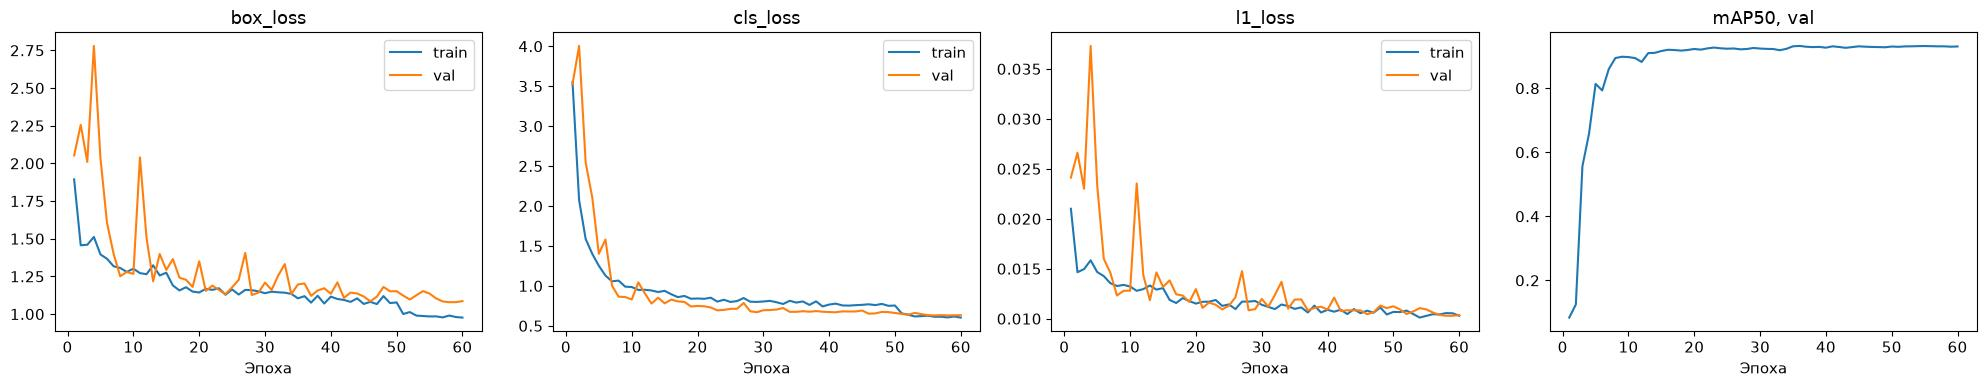

Лучший mAP50-95 val на эпохе: 57


In [22]:
history = read_results(run_dir)
loss_components = [k.split('/', 1)[1] for k in history if k.startswith('train/') and 'loss' in k]
fig, axes = plt.subplots(1, len(loss_components) + 1, figsize=(5 * (len(loss_components) + 1), 4))
for ax, component in zip(axes, loss_components):
    for split in ('train', 'val'):
        key = f'{split}/{component}'
        if key in history:
            ax.plot(history['epoch'], history[key], label=split)
    ax.set_title(component)
    ax.set_xlabel('Эпоха')
    ax.legend()
axes[-1].plot(history['epoch'], history['metrics/mAP50(B)'])
axes[-1].set_title('mAP50, val')
axes[-1].set_xlabel('Эпоха')
plt.tight_layout()
plt.show()
print('Лучший mAP50-95 val на эпохе:', int(history['epoch'][history['metrics/mAP50-95(B)'].argmax()]))

Ответ: Обучал модель 60 эпох с размером входа 640 и batch 16. Такое разрешение оставляет больше деталей у мелких тромбоцитов, а batch помещается в память RTX 5070. Выбрал AdamW с начальным шагом 0.001, прогревом в течение трех эпох и снижением шага до 5 процентов от начального значения.

Добавил повороты до 90 градусов и отражения по обеим осям, поскольку ориентация клеток на таких снимках не важна. Изменения цвета оставил умеренными, а mosaic отключил на последних десяти эпохах. Проверка на val шла после каждой эпохи, patience поставил 20, seed оставил 0.

Обучение заняло 6.47 минуты, лучший mAP50-95 на val получился на 57-й эпохе. Ошибка рамок на val снизилась с 2.053 до 1.086, ошибка классов с 3.525 до 0.633, а l1 loss с 0.024 до 0.010. К концу ошибки на val не начали устойчиво расти, поэтому явного переобучения по графикам не видно. При этом лучший результат получен почти в конце, так что я бы попробовал больше эпох, прежде чем считать обучение законченным.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 289.4±41.9 MB/s, size: 20.9 KB)


val: Scanning C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo\labels\val... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 2.1Kit/s 0.0s

val: New cache created: C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo\labels\val.cache


... (22 outputs left out)

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


{
  "map50": 0.9389762938423033,
  "map50_95": 0.6320287667896428,
  "precision": 0.8725226253837571,
  "recall": 0.9123188405797101,
  "per_class": {
    "RBC": {
      "map50": 0.911760423363699,
      "map50_95": 0.6550987496228395,
      "precision": 0.81743114441096,
      "recall": 0.8369565217391305
    },
    "WBC": {
      "map50": 0.995,
      "map50_95": 0.7630007335782816,
      "precision": 0.9892002270978106,
      "recall": 1.0
    },
    "Platelets": {
      "map50": 0.9101684581632108,
      "map50_95": 0.4779868171678071,
      "precision": 0.8109365046425004,
      "recall": 0.9
    }
  },
  "split": "test",
  "custom_map50": 0.9213256311368552
}


Val: {'map50': 0.9307878869612211, 'map50_95': 0.6255117276633674, 'precision': 0.8634646114781105, 'recall': 0.9173588334607494, 'per_class': {'RBC': {'map50': 0.8577874732190527, 'map50_95': 0.6131103387546849, 'precision': 0.75312568334431, 'recall': 0.8181818181818182}, 'WBC': {'map50': 0.995, 'map50_95': 0.7982583734599482, 'precision': 0.9887165082794541, 'recall': 1.0}, 'Platelets': {'map50': 0.9395761876646108, 'map50_95': 0.46516647077546924, 'precision': 0.8485516428105675, 'recall': 0.9338946822004301}}}
Разность собственного mAP50 и ultralytics: -0.017650662705448128


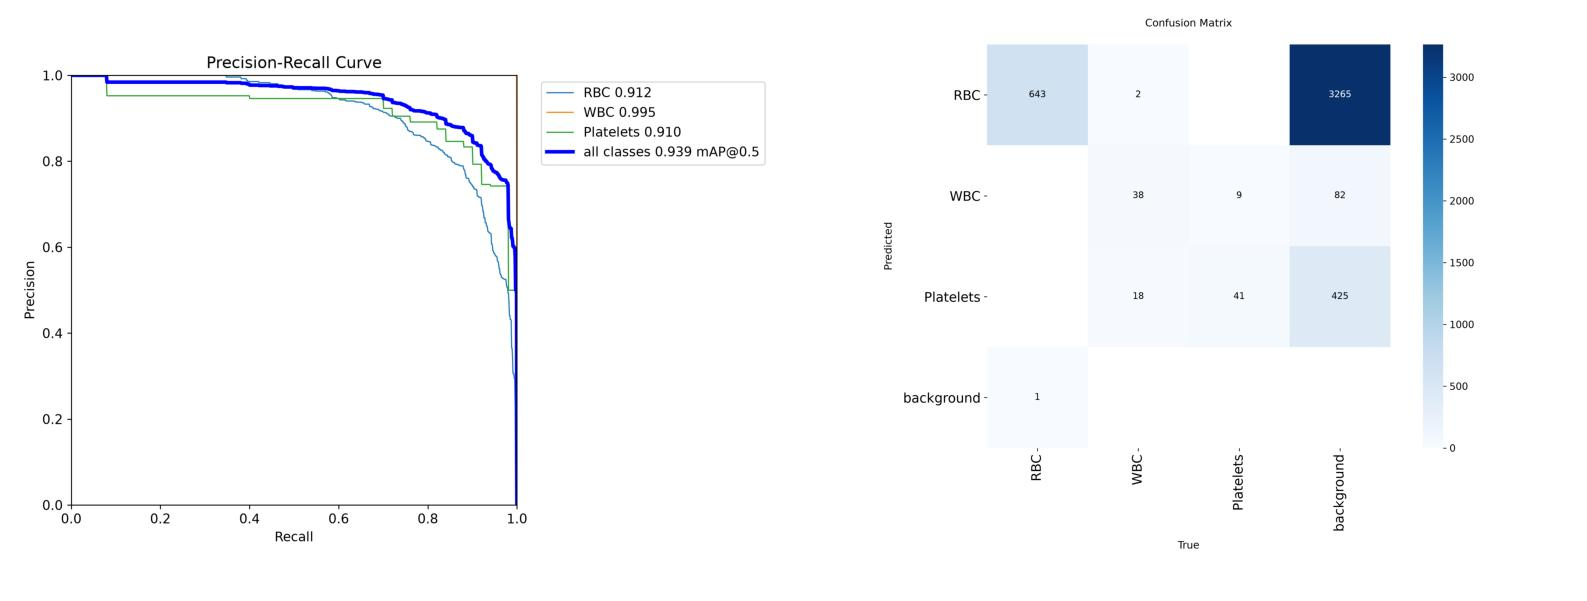

In [24]:
def pack_metrics(result):
    b = result.box
    return dict(map50=float(b.map50), map50_95=float(b.map), precision=float(b.mp), recall=float(b.mr),
                per_class={CLASSES[int(c)]: dict(map50=float(b.ap50[i]), map50_95=float(b.ap[i]),
                                                precision=float(b.p[i]), recall=float(b.r[i]))
                           for i, c in enumerate(b.ap_class_index)})


start = time.perf_counter()
validation = {split: val_metrics(best, split, f'final_{split}', plots=True, conf=0.001, end2end=True)
              for split in ('val', 'test') if split in records}
RUN_TIMES['validation'] = time.perf_counter() - start
FINAL = pack_metrics(validation[FINAL_SPLIT])
FINAL['split'] = FINAL_SPLIT
final_predictions = predict_records(best, records[FINAL_SPLIT], end2end=True)
custom_map50, custom_aps = evaluate_map50(final_predictions, records[FINAL_SPLIT], len(CLASSES))
FINAL['custom_map50'] = custom_map50
print(json.dumps(FINAL, ensure_ascii=False, indent=2))
print('Val:', pack_metrics(validation['val']))
print('Разность собственного mAP50 и ultralytics:', custom_map50 - FINAL['map50'])
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, filename in zip(axes, ('BoxPR_curve.png', 'confusion_matrix.png')):
    image_path = Path(validation[FINAL_SPLIT].save_dir) / filename
    if not image_path.exists():
        image_path = Path(validation[FINAL_SPLIT].save_dir) / filename.replace('BoxPR_', 'PR_')
    ax.imshow(plt.imread(image_path))
    ax.axis('off')
plt.tight_layout()
plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.939,
 'map50_95': 0.632,
 'precision': 0.8725,
 'recall': 0.9123,
 'split': 'test',
 'custom_map50': 0.9213}

Ответ: На тесте получились mAP50 0.9390, mAP50-95 0.6320, precision 0.8725 и recall 0.9123. Лучше всего модель находит WBC. По AP50-95 результат WBC равен 0.7630, RBC 0.6551, а Platelets 0.4780. С тромбоцитами сложнее: они маленькие, и даже небольшое смещение рамки сильно меняет IoU.

В матрице ошибок по столбцам идут настоящие классы, а по строкам предсказанные. Строка background показывает пропущенные объекты, столбец background показывает лишние предсказания. Матрица построена при conf 0.001, поэтому в ней много слабых предсказаний. Precision и recall в итоговой таблице относятся к другому порогу, который библиотека выбирает сама.

mAP50-95 ниже mAP50, потому что учитывает и более строгие требования к совпадению рамок, вплоть до IoU 0.95. Моя функция дала mAP50 0.9213, что на 0.0177 ниже результата Ultralytics. В ней иначе считается площадь под кривой и выбираются соответствия между рамками, поэтому полного совпадения я не ожидал. Еще может влиять разное добавление полей вокруг изображения в predict и val, но отдельно я это не проверял.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    intersection = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:]) -
                              np.maximum(a[:, None, :2], b[None, :, :2])).prod(axis=2)
    area_a = np.maximum(0, a[:, 2:] - a[:, :2]).prod(axis=1)
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    categories = np.full(len(pred['boxes']), 'background', dtype=object)
    used = np.zeros(len(gt['boxes']), dtype=bool)
    explained = np.zeros(len(gt['boxes']), dtype=bool)
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = np.asarray(gt['labels']) == pred['labels'][i]
        candidates = np.flatnonzero(same & ~used & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            used[j] = True
            categories[i] = 'tp'
            continue
        candidates = np.flatnonzero(~same & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            explained[j] = True
            categories[i] = 'class'
            continue
        candidates = np.flatnonzero(same & ~used & (ious[i] >= iou_loc) & (ious[i] < iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            explained[j] = True
            categories[i] = 'localization'
    return categories, np.flatnonzero(~used & ~explained)

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ошибки val при conf = 0.25 {'tp': 647, 'class': 0, 'localization': 31, 'background': 427, 'missed': 47}
{
  "RBC": {
    "tp": 541,
    "class": 0,
    "localization": 31,
    "background": 413,
    "missed": 43
  },
  "WBC": {
    "tp": 56,
    "class": 0,
    "localization": 0,
    "background": 0,
    "missed": 0
  },
  "Platelets": {
    "tp": 50,
    "class": 0,
    "localization": 0,
    "background": 14,
    "missed": 4
  }
}
class : примеров нет при выбранном пороге


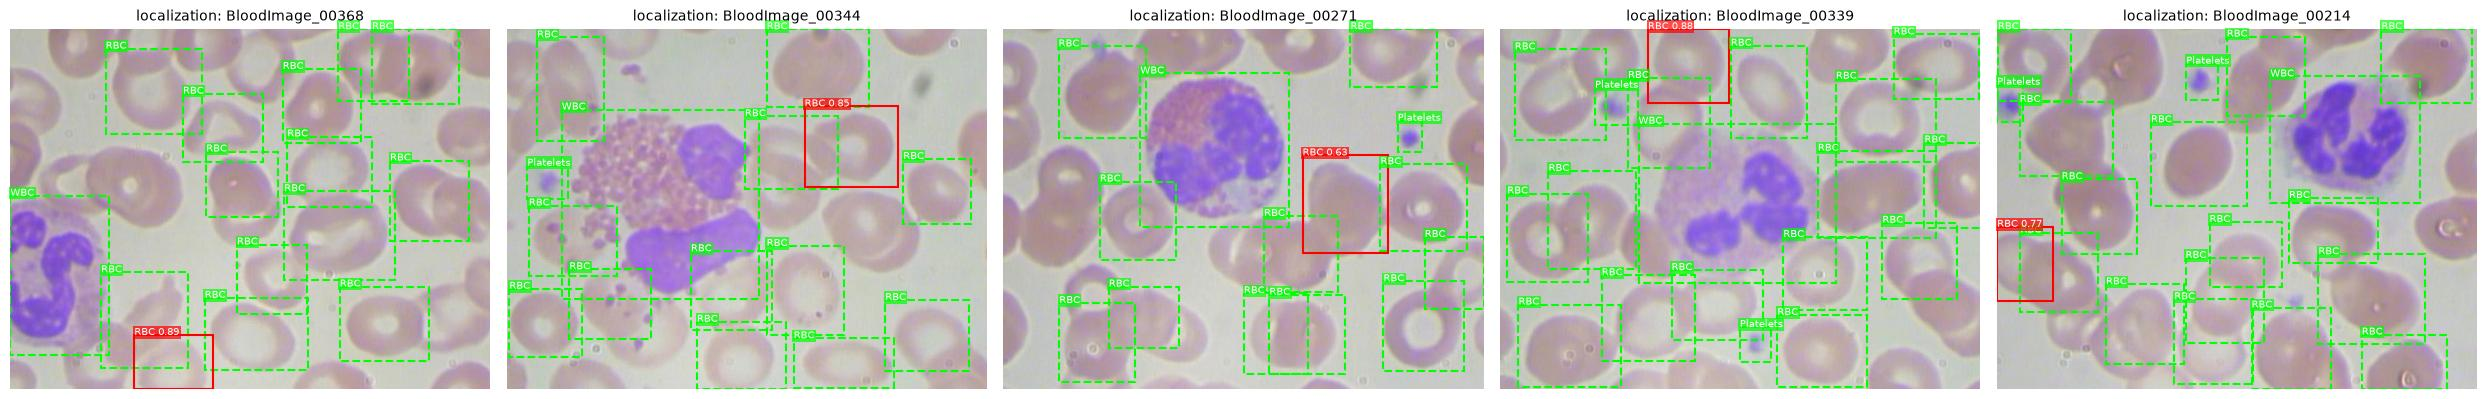

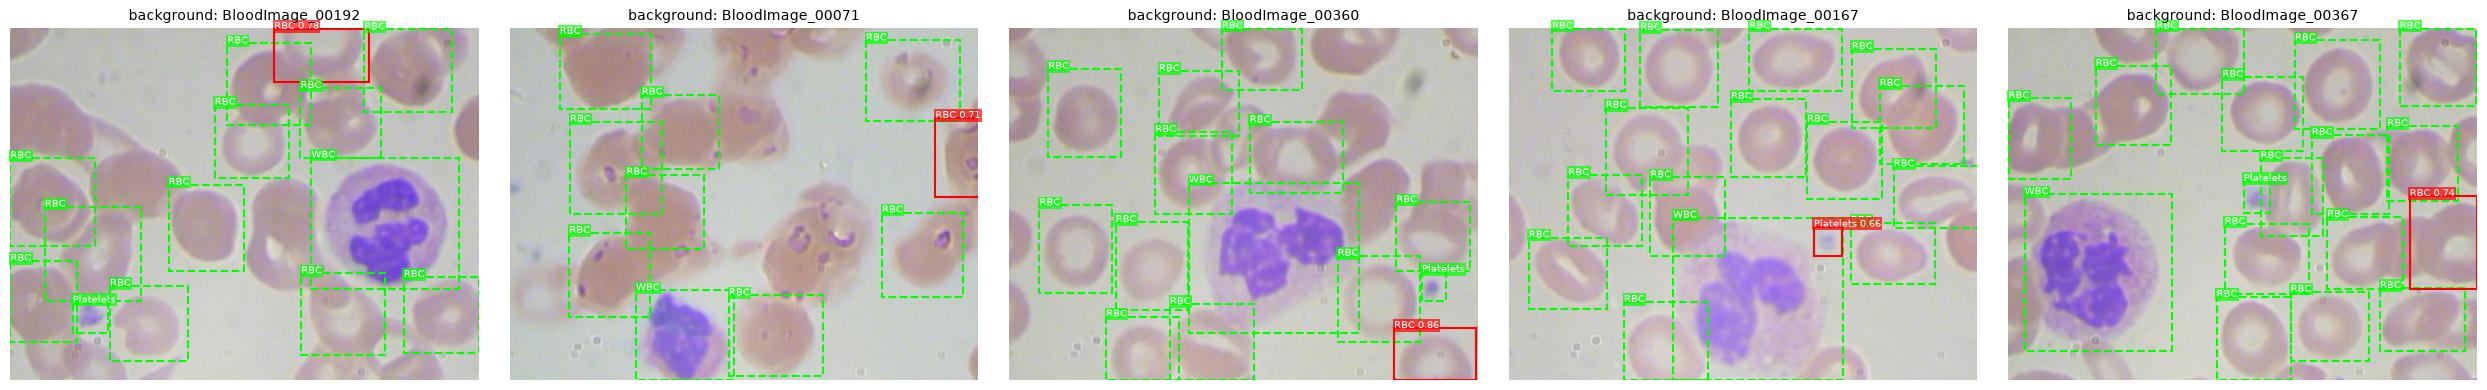

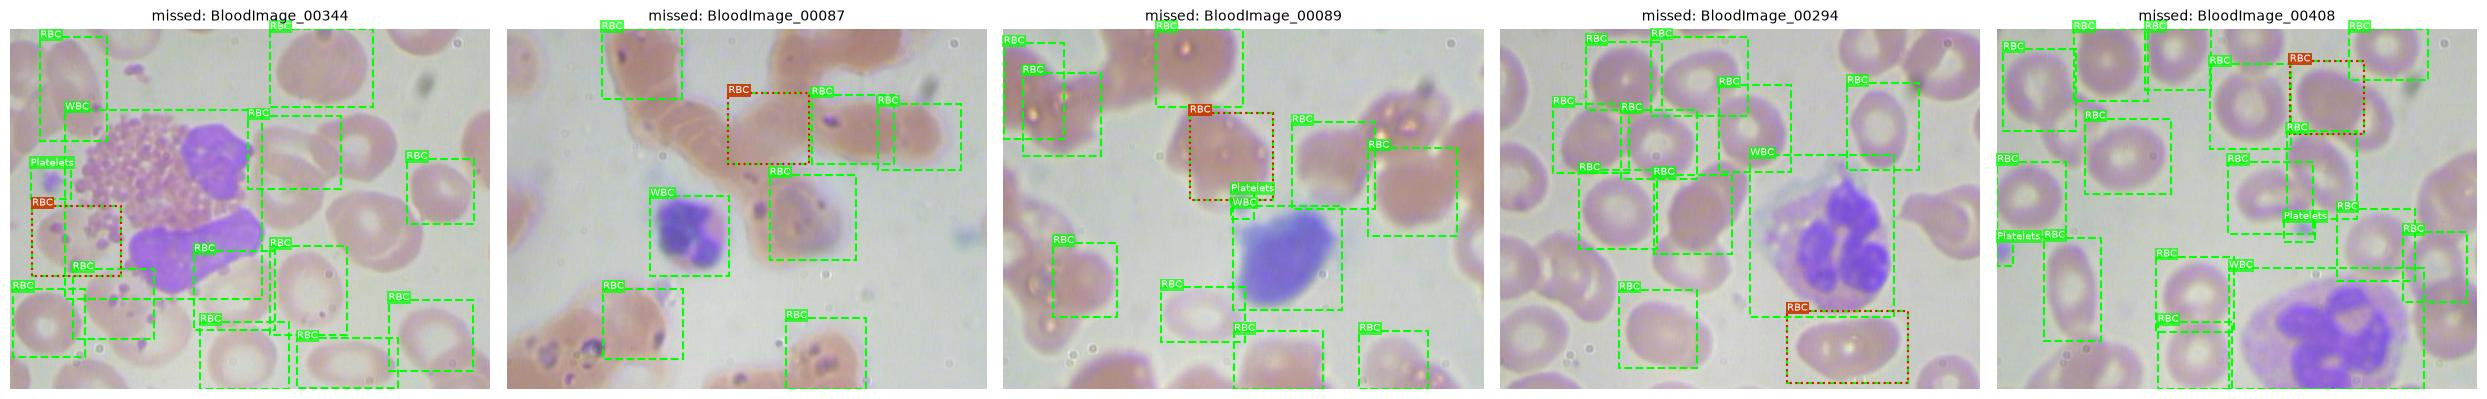

In [28]:
val_predictions = predict_records(best, records['val'], conf=CONF_ERRORS, end2end=True)
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
errors_by_class = {name: dict.fromkeys(ERROR_TYPES, 0) for name in CLASSES}
examples = {kind: [] for kind in ERROR_TYPES if kind != 'tp'}
for rec, pred in zip(records['val'], val_predictions):
    cats, missed = categorize_predictions(pred, rec)
    for i, category in enumerate(cats):
        ERRORS[category] += 1
        errors_by_class[CLASSES[pred['labels'][i]]][category] += 1
        if category != 'tp':
            examples[category].append((rec, pred, i))
    ERRORS['missed'] += len(missed)
    for i in missed:
        errors_by_class[CLASSES[rec['labels'][i]]]['missed'] += 1
        examples['missed'].append((rec, pred, i))
print('Ошибки val при conf =', CONF_ERRORS, ERRORS)
print(json.dumps(errors_by_class, ensure_ascii=False, indent=2))
for kind, cases in examples.items():
    unique = list({str(rec['image']): (rec, pred, i) for rec, pred, i in reversed(cases)}.values())[:5]
    if not unique:
        print(kind, ': примеров нет при выбранном пороге')
        continue
    fig, axes = plt.subplots(1, len(unique), figsize=(5 * len(unique), 4), squeeze=False)
    for ax, (rec, pred, i) in zip(axes.flat, unique):
        draw_boxes(ax, Image.open(rec['image']), rec['boxes'], rec['labels'], CLASSES,
                   color='lime', linestyle='--', title=f'{kind}: {Path(rec["image"]).stem}')
        if kind == 'missed':
            box, label = rec['boxes'][i:i + 1], rec['labels'][i:i + 1]
            draw_boxes(ax, None, box, label, CLASSES, color='red', linestyle=':')
        else:
            draw_boxes(ax, None, pred['boxes'][i:i + 1], pred['labels'][i:i + 1], CLASSES,
                       pred['scores'][i:i + 1], color='red')
    plt.tight_layout()
    plt.show()

Ответ: На val при conf 0.25 получилось 647 верных детекций, 31 ошибка положения рамки, 427 лишних предсказаний и 47 пропущенных объектов. Ошибок класса не нашлось, поэтому примеров для этой категории нет. На рисунках исходная разметка показана зеленым пунктиром, а выбранная ошибка красным.

Больше всего ошибок попало в background, но часть этих рамок стоит на настоящих клетках без разметки. Например, это видно у края BloodImage_00360 и BloodImage_00367. Также мешают перекрывающиеся клетки и нечеткие границы. Я бы сначала проверил полноту разметки и рамки пересекающихся RBC, затем добавил больше примеров мелких объектов и повторил сравнение разрешений с несколькими seed.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
ablation_args = {**TRAIN_ARGS, 'imgsz': 320}
ablation_model, ablation_time, ablation_dir = train_yolo('ablation_320', **ablation_args)
RUN_TIMES['ablation_train'] = ablation_time
ablation_best = YOLO(ablation_dir / 'weights/best.pt')
ablation_val = ablation_best.val(data=str(DATA_YAML), split='val', imgsz=320, batch=BATCH,
                               device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                               name='ablation_val', exist_ok=True, plots=False, verbose=False, end2end=True)
ABLATION = dict(factor='imgsz', split='val',
                main=dict(imgsz=IMGSZ, map50=float(validation['val'].box.map50),
                          map50_95=float(validation['val'].box.map), train_time_sec=RUN_TIMES['train']),
                alternative=dict(imgsz=320, map50=float(ablation_val.box.map50),
                                 map50_95=float(ablation_val.box.map), train_time_sec=ablation_time),
                train_args=ablation_args)
print(json.dumps(ABLATION, ensure_ascii=False, indent=2))

Используется завершенное обучение ablation_320, число эпох: 60
WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 275.9±48.6 MB/s, size: 20.8 KB)


val: Scanning C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo\labels\val.cache... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 16.2Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 1.9it/s 0.2s<1.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 75% ━━━━━━━━━─── 3/4 4.7it/s 0.3s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 9.2it/s 0.4s

                   all         54        704      0.814      0.897      0.913      0.613


Speed: 0.1ms preprocess, 3.3ms inference, 0.0ms loss, 0.2ms postprocess per image


{
  "factor": "imgsz",
  "split": "val",
  "main": {
    "imgsz": 640,
    "map50": 0.9307878869612211,
    "map50_95": 0.6255117276633674,
    "train_time_sec": 388.0350628999986
  },
  "alternative": {
    "imgsz": 320,
    "map50": 0.9126811498206234,
    "map50_95": 0.6125700786507754,
    "train_time_sec": 282.6390242000016
  },
  "train_args": {
    "epochs": 60,
    "imgsz": 320,
    "batch": 16,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.05,
    "weight_decay": 0.0005,
    "warmup_epochs": 3,
    "patience": 20,
    "mosaic": 0.5,
    "close_mosaic": 10,
    "mixup": 0.0,
    "degrees": 90,
    "flipud": 0.5,
    "fliplr": 0.5,
    "hsv_h": 0.01,
    "hsv_s": 0.2,
    "hsv_v": 0.2,
    "translate": 0.1,
    "scale": 0.3,
    "seed": 0,
    "deterministic": true,
    "val": true,
    "plots": true,
    "amp": true,
    "cache": false,
    "end2end": true
  }
}


Ответ: Для сравнения я уменьшил размер входа с 640 до 320, а остальные настройки оставил прежними. На val при 640 получились mAP50 0.9308 и mAP50-95 0.6255, при 320 они снизились до 0.9127 и 0.6126. Зато обучение заняло 4.71 минуты вместо 6.47, то есть стало примерно на четверть быстрее.

При уменьшении изображения теряются мелкие детали, поэтому такой результат выглядит ожидаемым, особенно для тромбоцитов. Но по одному запуску на 54 изображениях нельзя уверенно сказать, какая часть разницы связана именно с разрешением. Я бы повторил оба варианта с несколькими seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

Ответ: После дообучения YOLO26n на BCCD mAP50 на тесте вырос до 0.9390, а mAP50-95 составил 0.6320. Для сравнения, исходная COCO-модель не содержит нужных классов и дает ноль, а простой алгоритм по цвету набирает 0.2817. Лучше всего распознаются лейкоциты, сложнее всего точно обвести маленькие тромбоциты. В разборе ошибок больше всего лишних предсказаний, причем часть из них относится к клеткам без исходной разметки. Уменьшение входа до 320 ускорило обучение, но немного снизило качество на val. Результаты пока ограничены маленькой валидационной выборкой, одним seed, дисбалансом классов и отсутствием разбиения по пациентам. Дальше я бы проверил разметку и повторил обучение с несколькими seed на более независимых снимках.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['ablation_results.csv', 'analysis.json', 'BCCD_LICENSE.txt', 'best.onnx', 'best.pt', 'export.json', 'extra50.json', 'extra50_results.csv', 'metrics.json', 'results.csv', 'rtdetr.json', 'rtdetr_results.csv', 'splits.json', 'test_BoxF1_curve.png', 'test_BoxP_curve.png', 'test_BoxPR_curve.png', 'test_BoxR_curve.png', 'test_confusion_matrix.png', 'test_confusion_matrix_normalized.png', 'val_BoxF1_curve.png', 'val_BoxP_curve.png', 'val_BoxPR_curve.png', 'val_BoxR_curve.png', 'val_confusion_matrix.png', 'val_confusion_matrix_normalized.png']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

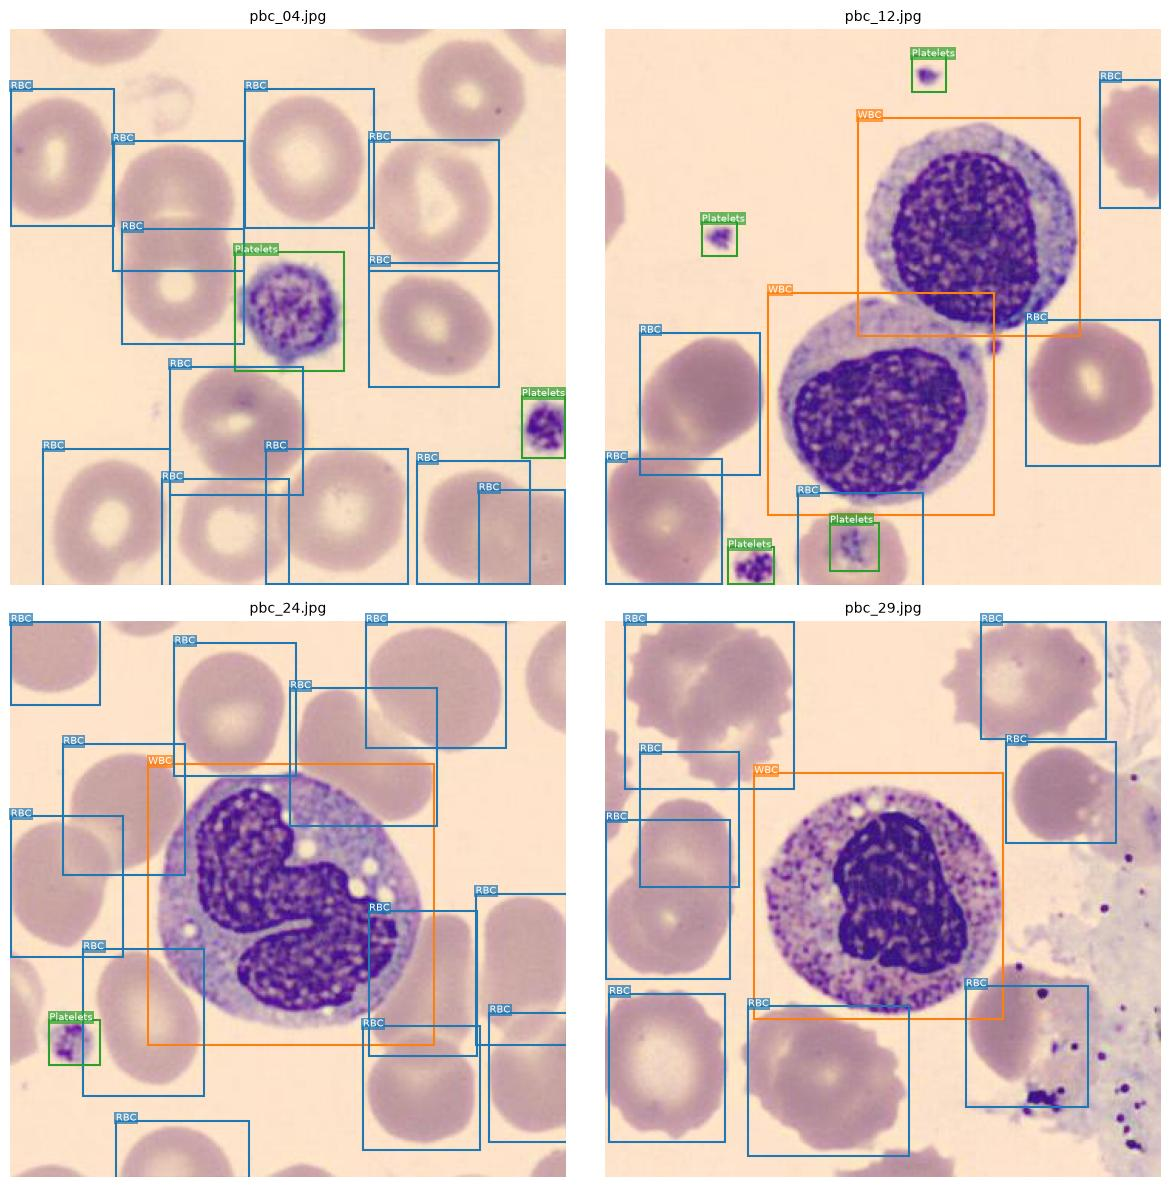

Используется завершенное обучение finetune_extra50, число эпох: 60
WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 224.6±18.4 MB/s, size: 20.4 KB)


val: Scanning C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo_extra50\labels\val... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 2.1Kit/s 0.0s

val: New cache created: C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo_extra50\labels\val.cache


... (4 outputs left out)

                   all         54        704      0.861      0.928      0.932      0.638


Speed: 0.2ms preprocess, 7.6ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\extra50_val


{
  "source": "https://data.mendeley.com/datasets/snkd93bnjr/1",
  "mirror": "https://huggingface.co/datasets/nirschl-lab/acevedo_et_al_2020",
  "license": "CC BY 4.0",
  "n_new_images": 50,
  "n_train_before": 254,
  "n_train_after": 304,
  "annotation_seconds": 523.8943316936493,
  "annotation_counts": {
    "WBC": 48,
    "RBC": 558,
    "Platelets": 43
  },
  "train_seconds": 412.5058696999986,
  "train_args": {
    "epochs": 60,
    "imgsz": 640,
    "batch": 16,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.05,
    "weight_decay": 0.0005,
    "warmup_epochs": 3,
    "patience": 20,
    "mosaic": 0.5,
    "close_mosaic": 10,
    "mixup": 0.0,
    "degrees": 90,
    "flipud": 0.5,
    "fliplr": 0.5,
    "hsv_h": 0.01,
    "hsv_s": 0.2,
    "hsv_v": 0.2,
    "translate": 0.1,
    "scale": 0.3,
    "seed": 0,
    "deterministic": true,
    "val": true,
    "plots": true,
    "amp": true,
    "cache": false,
    "end2end": true
  },
  "before": {
    "map50": 0.930787886961

In [31]:
if '6.1' in BONUS_TASKS:
    EXTRA_ROOT = Path('extra')
    extra_manifest = json.loads((EXTRA_ROOT / 'manifest.json').read_text(encoding='utf-8'))
    annotation_session = json.loads((EXTRA_ROOT / 'annotation_session.json').read_text(encoding='utf-8'))
    original_hashes = {hashlib.sha256(Image.open(r['image']).convert('RGB').tobytes()).hexdigest()
                       for recs in records.values() for r in recs}
    extra_recs = []
    extra_hashes = set()
    for item in extra_manifest['images']:
        image_path = EXTRA_ROOT / 'images' / item['image']
        assert hashlib.sha256(image_path.read_bytes()).hexdigest() == item['sha256']
        with Image.open(image_path) as image:
            width, height = image.size
            digest = hashlib.sha256(image.convert('RGB').tobytes()).hexdigest()
        assert digest not in original_hashes and digest not in extra_hashes
        extra_hashes.add(digest)
        boxes, labels = from_yolo((EXTRA_ROOT / 'labels' / f'{image_path.stem}.txt').read_text(), width, height)
        assert len(boxes) and np.isfinite(boxes).all()
        assert (boxes[:, 2:] > boxes[:, :2]).all()
        assert ((labels >= 0) & (labels < len(CLASSES))).all()
        assert (boxes >= -0.001).all() and (boxes <= [width + 0.001, height + 0.001, width + 0.001, height + 0.001]).all()
        extra_recs.append(dict(image=image_path, width=width, height=height, boxes=boxes, labels=labels))
    assert len(extra_recs) == 50
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    for ax, i in zip(axes.flat, (4, 12, 24, 29)):
        r = extra_recs[i]
        draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, title=Path(r['image']).name)
    plt.tight_layout()
    plt.show()
    base_yolo_root, base_yaml = YOLO_ROOT, DATA_YAML
    YOLO_ROOT = DATA_ROOT / 'yolo_extra50'
    for split, recs in records.items():
        export_split(recs + extra_recs if split == 'train' else recs, split)
    DATA_YAML = YOLO_ROOT / 'data.yaml'
    DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n' +
                         ''.join(f'{s}: images/{s}\n' for s in records) +
                         'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
    extra_yaml = DATA_YAML
    try:
        extra_model, extra_time, extra_dir = train_yolo('finetune_extra50', **TRAIN_ARGS)
    finally:
        YOLO_ROOT, DATA_YAML = base_yolo_root, base_yaml
    extra_best = YOLO(extra_dir / 'weights/best.pt')
    extra_val = extra_best.val(data=str(extra_yaml), split='val', imgsz=IMGSZ, batch=BATCH,
                               device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                               name='extra50_val', exist_ok=True, plots=True, verbose=False,
                               conf=0.001, end2end=True)
    extra_report = dict(source=extra_manifest['source'], mirror=extra_manifest['mirror'], license=extra_manifest['license'],
                        n_new_images=len(extra_recs), n_train_before=len(records['train']),
                        n_train_after=len(records['train']) + len(extra_recs),
                        annotation_seconds=annotation_session['total_annotation_and_review_seconds'],
                        annotation_counts=annotation_session['objects'],
                        train_seconds=extra_time, train_args=TRAIN_ARGS,
                        before=pack_metrics(validation['val']), after=pack_metrics(extra_val),
                        split='val', epochs=len(read_results(extra_dir)['epoch']))
    RUN_TIMES['extra50_train'] = extra_time
    print(json.dumps(json_ready(extra_report), ensure_ascii=False, indent=2))
    (artifact_dir / 'extra50.json').write_text(json.dumps(json_ready(extra_report), ensure_ascii=False, indent=2), encoding='utf-8')
    shutil.copy2(extra_dir / 'results.csv', artifact_dir / 'extra50_results.csv')
    for image_path in Path(extra_val.save_dir).glob('*.png'):
        shutil.copy2(image_path, artifact_dir / f'extra50_{image_path.name}')
    if (extra_dir / 'results.png').exists():
        shutil.copy2(extra_dir / 'results.png', artifact_dir / 'extra50_learning_curves.png')


Ответ: Я добавил 50 новых снимков из [PBC](https://data.mendeley.com/datasets/snkd93bnjr/1), взятых через [зеркало MicroBench](https://huggingface.co/datasets/nirschl-lab/acevedo_et_al_2020). У изображений лицензия CC BY 4.0, авторы указаны в extra/README.txt. Рамки расставил после просмотра изображений, сохранил в формате Label Studio и экспортировал в YOLO. Получилось 558 RBC, 48 WBC и 43 Platelets, просмотр и проверка заняли 8.7 минуты. Сложнее всего было решать, где заканчиваются перекрывающиеся клетки и какие маленькие фиолетовые точки считать тромбоцитами. У края отмечал клетки, у которых видна примерно половина или больше.

Обучающая часть выросла с 254 до 304 изображений, настройки обучения оставил прежними, val не менял. После 60 эпох mAP50 на val изменился с 0.9308 до 0.9316, а mAP50-95 с 0.6255 до 0.6376. Новое обучение заняло 6.88 минуты. Для этого опыта время на разметку оказалось полезным, качество на val выросло. Но я бы повторил обучение с несколькими seed, чтобы проверить, повторится ли этот результат.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR
    rt_weights = 'rtdetr-l.pt'
    rt_initial = RTDETR(rt_weights)
    rt_initial_params = sum(p.numel() for p in rt_initial.model.parameters())
    rt_args = {**TRAIN_ARGS, 'batch': 4, 'lr0': 0.0001, 'weight_decay': 0.0001,
               'mosaic': 0.0, 'close_mosaic': 0}
    rt_args.pop('end2end', None)
    rt_dir = RUNS.resolve() / 'rtdetr_l'
    rt_signature = experiment_signature(rt_weights, rt_args)
    rt_marker = rt_dir / 'completed.json'
    if REUSE_COMPLETED_RUNS and rt_marker.exists() and json.loads(rt_marker.read_text())['signature'] == rt_signature:
        rt_time = json.loads(rt_marker.read_text())['seconds']
        print('Используется завершенное обучение RT-DETR')
    else:
        start = time.perf_counter()
        rt_initial.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS,
                         project=str(RUNS.resolve()), name='rtdetr_l', exist_ok=True, verbose=False, **rt_args)
        rt_time = time.perf_counter() - start
        rt_dir = Path(rt_initial.trainer.save_dir)
        rt_epochs = len(read_results(rt_dir)['epoch'])
        rt_marker.write_text(json.dumps(dict(signature=rt_signature, seconds=rt_time, epochs=rt_epochs)), encoding='utf-8')
    del rt_initial
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    rt_best = RTDETR(rt_dir / 'weights/best.pt')
    rt_trained_params = sum(p.numel() for p in rt_best.model.parameters())
    rt_metrics = rt_best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=4,
                             device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                             name='rtdetr_val', exist_ok=True, plots=True, verbose=False, conf=0.001)
    def latency_ms(detector, predict_args, warmup=5, repeats=30):
        image = Image.open(records['val'][0]['image']).convert('RGB')
        values = []
        for i in range(warmup + repeats):
            if torch.cuda.is_available() and predict_args.get('device') != 'cpu':
                torch.cuda.synchronize()
            start = time.perf_counter()
            detector.predict(image, imgsz=IMGSZ, batch=1, verbose=False, conf=0.001, **predict_args)
            if torch.cuda.is_available() and predict_args.get('device') != 'cpu':
                torch.cuda.synchronize()
            if i >= warmup:
                values.append((time.perf_counter() - start) * 1000)
        return dict(mean_ms=float(np.mean(values)), median_ms=float(np.median(values)),
                    std_ms=float(np.std(values)), repeats=repeats, warmup=warmup)
    rt_latency = latency_ms(rt_best, dict(device=DEVICE))
    yolo_latency = latency_ms(YOLO(run_dir / 'weights/best.pt'), dict(device=DEVICE, nms=False, rect=False))
    rt_report = dict(model=rt_weights, weights_sha256=hashlib.sha256(Path(rt_weights).read_bytes()).hexdigest(),
                     params=rt_trained_params, params_pretrained=rt_initial_params, train_seconds=rt_time, epochs=len(read_results(rt_dir)['epoch']),
                     metrics=pack_metrics(rt_metrics), latency=rt_latency,
                     yolo_latency=yolo_latency, yolo_metrics=pack_metrics(validation['val']),
                     yolo_params=sum(p.numel() for p in YOLO(run_dir / 'weights/best.pt').model.parameters()),
                     train_args=rt_args, split='val', n_train=len(records['train']), n_val=len(records['val']), device=DEVICE_NAME)
    RUN_TIMES['rtdetr_train'] = rt_time
    print(json.dumps(json_ready(rt_report), ensure_ascii=False, indent=2))
    (artifact_dir / 'rtdetr.json').write_text(json.dumps(json_ready(rt_report), ensure_ascii=False, indent=2), encoding='utf-8')
    shutil.copy2(rt_dir / 'results.csv', artifact_dir / 'rtdetr_results.csv')
    for image_path in Path(rt_metrics.save_dir).glob('*.png'):
        shutil.copy2(image_path, artifact_dir / f'rtdetr_{image_path.name}')
    if (rt_dir / 'results.png').exists():
        shutil.copy2(rt_dir / 'results.png', artifact_dir / 'rtdetr_learning_curves.png')


Используется завершенное обучение RT-DETR


Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)


rt-detr-l summary (fused): 315 layers, 31,989,905 parameters, 0 gradients, 105.3 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 265.1±38.5 MB/s, size: 20.4 KB)


val: Scanning C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\yolo\labels\val.cache... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 28.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/14 2.2it/s 0.1s<6.0s

... (12 outputs left out)

                   all         54        704      0.192      0.722      0.387      0.253


Speed: 0.5ms preprocess, 22.8ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\rtdetr_val


{
  "model": "rtdetr-l.pt",
  "weights_sha256": "6de60b10d4bc566f00cda0f5b4d64afe4b66d48dc9695d2171effb7859d8e73f",
  "params": 32812241,
  "params_pretrained": 32970476,
  "train_seconds": 1771.4821462,
  "epochs": 60,
  "metrics": {
    "map50": 0.3873971553338782,
    "map50_95": 0.25255666955130246,
    "precision": 0.19183326715706864,
    "recall": 0.7224226390893058,
    "per_class": {
      "RBC": {
        "map50": 0.718047861162514,
        "map50_95": 0.4906560000482683,
        "precision": 0.3007711449636667,
        "recall": 0.9410774410774411
      },
      "WBC": {
        "map50": 0.19226675350594546,
        "map50_95": 0.12590592930517738,
        "precision": 0.1253838575985131,
        "recall": 0.39285714285714285
      },
      "Platelets": {
        "map50": 0.25187685133317517,
        "map50_95": 0.14110807930046176,
        "precision": 0.14934479890902622,
        "recall": 0.8333333333333334
      }
    }
  },
  "latency": {
    "mean_ms": 39.3999899995833

Ответ: Я дообучил [RT-DETR-L](https://docs.ultralytics.com/models/rtdetr/) на исходных 254 изображениях и проверил на той же val из 54 снимков. Вход оставил 640, batch уменьшил до 4, поскольку модель тяжелее. Для AdamW взял начальный шаг 0.0001, mosaic отключил. Обучение шло 60 эпох и заняло 29.52 минуты, у YOLO было 60 эпох и 6.47 минуты.

У дообученной RT-DETR 32.81 млн параметров, у YOLO 2.53 млн. На val RT-DETR получил mAP50 0.3874 и mAP50-95 0.2526, YOLO получил 0.9308 и 0.6255. После прогрева обработка одной картинки на RTX 5070 в среднем заняла 39.40 мс у RT-DETR и 17.15 мс у YOLO. В обоих случаях считал весь predict с batch 1, а не только проход по слоям.

В этом запуске RT-DETR уступил YOLO по качеству. По PR-кривым особенно слабо получились редкие классы WBC и Platelets. Для этой небольшой выборки я бы оставил YOLO, поскольку она быстрее обучается и работает. RT-DETR выбрал бы, если после подбора настроек он заметно выигрывал бы на val, а дополнительная память и задержка были бы допустимы. По одному запуску с разными настройками нельзя решить, какая архитектура лучше вообще.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if '6.3' in BONUS_TASKS:
    robustness = {}
    corruptions = {'brightness_0.5': lambda im: ImageEnhance.Brightness(im).enhance(0.5),
                   'blur_2': lambda im: im.filter(ImageFilter.GaussianBlur(2)),
                   'jpeg_10': lambda im: im}
    for name, transform in corruptions.items():
        corrupt_root = DATA_ROOT / 'corruptions' / name
        (corrupt_root / 'images/val').mkdir(parents=True, exist_ok=True)
        (corrupt_root / 'labels/val').mkdir(parents=True, exist_ok=True)
        for r in records['val']:
            im = transform(Image.open(r['image']).convert('RGB'))
            im.save(corrupt_root / 'images/val' / Path(r['image']).name,
                    quality=10 if name == 'jpeg_10' else 95)
            shutil.copy2(YOLO_ROOT / 'labels/val' / f'{Path(r["image"]).stem}.txt', corrupt_root / 'labels/val')
        yaml_path = corrupt_root / 'data.yaml'
        yaml_path.write_text(f'path: {corrupt_root.resolve().as_posix()}\ntrain: {YOLO_ROOT.resolve().as_posix()}/images/train\nval: images/val\n' +
                             'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
        result = best.val(data=str(yaml_path), split='val', imgsz=IMGSZ, batch=BATCH,
                          device=DEVICE, workers=WORKERS, plots=False, verbose=False,
                          project=str(RUNS.resolve()), name=name, exist_ok=True, end2end=True)
        robustness[name] = pack_metrics(result)
    print(json.dumps(robustness, ensure_ascii=False, indent=2))

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 383.2±52.8 MB/s, size: 33.2 KB)


val: Scanning C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\corruptions\brightness_0.5\labels\val... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 1.3Kit/s 0.0s

val: New cache created: C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\data\corruptions\brightness_0.5\labels\val.cache


... (26 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 11.4it/s 0.4s

                   all         54        704      0.714       0.53      0.583      0.259


Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 0.2ms postprocess per image


{
  "brightness_0.5": {
    "map50": 0.9081410062182842,
    "map50_95": 0.5881980725078845,
    "precision": 0.8354032031293972,
    "recall": 0.8767961446571838,
    "per_class": {
      "RBC": {
        "map50": 0.8319781339252456,
        "map50_95": 0.5736977232018041,
        "precision": 0.7277967209376073,
        "recall": 0.82996632996633
      },
      "WBC": {
        "map50": 0.995,
        "map50_95": 0.7486238261235751,
        "precision": 0.950762256176804,
        "recall": 1.0
      },
      "Platelets": {
        "map50": 0.8974448847296069,
        "map50_95": 0.4422726681982739,
        "precision": 0.82765063227378,
        "recall": 0.8004221040052216
      }
    }
  },
  "blur_2": {
    "map50": 0.9258033419762713,
    "map50_95": 0.6046557616757336,
    "precision": 0.8206945695658963,
    "recall": 0.9444444444444443,
    "per_class": {
      "RBC": {
        "map50": 0.8551933901304651,
        "map50_95": 0.5791707379879253,
        "precision": 0.690049292

Ответ: Без искажений на val получились mAP50 0.9308 и mAP50-95 0.6255. При уменьшении яркости вдвое они снизились до 0.9081 и 0.5882, при размытии до 0.9258 и 0.6047. Сильнее всего повлияло JPEG-сжатие с качеством 10: метрики упали до 0.5830 и 0.2586. После такого сжатия теряются детали и появляются артефакты, из-за которых труднее находить мелкие клетки и их границы.

Размер и положение изображений не менялись, поэтому рамки я оставил прежними. В обучение можно было бы добавить умеренное сжатие, размытие и изменения яркости. Поможет ли это, нужно проверить отдельным обучением и сравнением на чистой val.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    if any(importlib.util.find_spec(name) is None for name in ('onnx', 'onnxruntime', 'onnxscript')):
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'onnx', 'onnxruntime', 'onnxscript'], check=True)
    import onnx
    import onnxruntime as ort
    export_model = YOLO(run_dir / 'weights/best.pt')
    onnx_path = Path(export_model.export(format='onnx', imgsz=IMGSZ, batch=1, dynamic=False,
                                        simplify=False, opset=20, device='cpu', nms=False))
    onnx.checker.check_model(str(onnx_path))
    cpu_pt = YOLO(run_dir / 'weights/best.pt')
    cpu_onnx = YOLO(onnx_path, task='detect')
    session_options = ort.SessionOptions()
    session_options.intra_op_num_threads = 8
    session_options.inter_op_num_threads = 1
    session_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    ort_session = ort.InferenceSession(str(onnx_path), sess_options=session_options, providers=['CPUExecutionProvider'])
    benchmark_image = Image.open(records['val'][0]['image']).convert('RGB').resize((IMGSZ, IMGSZ))
    benchmark_array = np.ascontiguousarray(np.asarray(benchmark_image, dtype=np.float32).transpose(2, 0, 1)[None] / 255)
    benchmark_tensor = torch.from_numpy(benchmark_array)
    torch_forward = YOLO(run_dir / 'weights/best.pt').model.to('cpu').eval()
    torch_forward.end2end = True
    torch_forward.fuse(verbose=False)
    def measure_forward(call):
        values = []
        with torch.inference_mode():
            for i in range(50):
                start = time.perf_counter()
                call()
                if i >= 10:
                    values.append((time.perf_counter() - start) * 1000)
        return dict(mean_ms=float(np.mean(values)), median_ms=float(np.median(values)),
                    std_ms=float(np.std(values)), repeats=40, warmup=10)
    cpu_pt_latency = measure_forward(lambda: torch_forward(benchmark_tensor))
    cpu_onnx_latency = measure_forward(lambda: ort_session.run(None, {ort_session.get_inputs()[0].name: benchmark_array}))
    cpu_results = {}
    for name, detector in [('pytorch', cpu_pt), ('onnx', cpu_onnx)]:
        result = detector.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device='cpu',
                              workers=0, project=str(RUNS.resolve()), name=f'export_{name}', exist_ok=True,
                              plots=False, verbose=False, conf=0.001, rect=False, nms=False)
        cpu_results[name] = pack_metrics(result)
    export_report = dict(format='ONNX', onnx_version=onnx.__version__, runtime=ort.__version__,
                         device='CPU', torch_threads=torch.get_num_threads(), onnx_threads=8, precision='FP32',
                         protocol='Forward only, same input tensor, 10 warmups, 40 repeats, median',
                         imgsz=IMGSZ, batch=1, rect=False, split='val',
                         latency_pytorch=cpu_pt_latency, latency_onnx=cpu_onnx_latency,
                         speedup=cpu_pt_latency['median_ms'] / cpu_onnx_latency['median_ms'],
                         pytorch=cpu_results['pytorch'], onnx=cpu_results['onnx'],
                         map50_delta=cpu_results['onnx']['map50'] - cpu_results['pytorch']['map50'],
                         file_size_mb=onnx_path.stat().st_size / 1024 ** 2,
                         onnx_sha256=hashlib.sha256(onnx_path.read_bytes()).hexdigest())
    assert export_report['map50_delta'] >= -0.001, export_report['map50_delta']
    print(json.dumps(json_ready(export_report), ensure_ascii=False, indent=2))
    shutil.copy2(onnx_path, artifact_dir / 'best.onnx')
    (artifact_dir / 'export.json').write_text(json.dumps(json_ready(export_report), ensure_ascii=False, indent=2), encoding='utf-8')

Ultralytics 8.4.182  Python-3.14.7 torch-2.11.0+cu130 CPU (Intel Core i7-10700K 3.80GHz)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs



PyTorch: starting from 'C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)



ONNX: starting export with onnx 1.23.2 opset 20...


ONNX: export success  1.1s, saved as 'C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete\weights\best.onnx' (9.4 MB)



Export complete (1.4s)
Results saved to C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete\weights\best.onnx
Predict:         yolo predict task=detect model=C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete\weights\best.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\Users\Aidors\Documents\Codex\2026-11-22\c-users-aidors-desktop-hw2-students\work\execution\runs_hw2\finetune_complete\weights\best.onnx imgsz=640 data=data\yolo\data.yaml 
Visualize:       https://netron.app


... (49 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 54/54 29.7it/s 1.8s

                   all         54        704      0.837      0.901      0.908      0.614


Speed: 2.2ms preprocess, 24.4ms inference, 0.0ms loss, 0.2ms postprocess per image


{
  "format": "ONNX",
  "onnx_version": "1.23.2",
  "runtime": "1.32.0",
  "device": "CPU",
  "torch_threads": 8,
  "onnx_threads": 8,
  "precision": "FP32",
  "protocol": "Forward only, same input tensor, 10 warmups, 40 repeats, median",
  "imgsz": 640,
  "batch": 1,
  "rect": false,
  "split": "val",
  "latency_pytorch": {
    "mean_ms": 55.913834999773826,
    "median_ms": 55.97920000036538,
    "std_ms": 2.667758061474434,
    "repeats": 40,
    "warmup": 10
  },
  "latency_onnx": {
    "mean_ms": 23.430212500261405,
    "median_ms": 23.03570000185573,
    "std_ms": 1.9498554752635593,
    "repeats": 40,
    "warmup": 10
  },
  "speedup": 2.43010631306432,
  "pytorch": {
    "map50": 0.9077297660326898,
    "map50_95": 0.6144510419611703,
    "precision": 0.8371577859953,
    "recall": 0.9012345679012346,
    "per_class": {
      "RBC": {
        "map50": 0.8308114824556178,
        "map50_95": 0.5945960738974623,
        "precision": 0.703245521683018,
        "recall": 0.79629629

Ответ: Я экспортировал лучшую YOLO в ONNX и сравнил ее с PyTorch на Intel Core i7-10700K. Для обеих версий использовал FP32, восемь потоков и один и тот же вход 640 на 640. Сначала сделал десять запусков для прогрева, потом сорок для замера. Здесь считается только проход модели, без чтения файла и подготовки картинки.

Медианная задержка PyTorch составила 55.98 мс, ONNX 23.04 мс. По медиане ONNX оказался быстрее в 2.43 раза. ONNX Runtime оптимизирует граф вычислений и использует свои реализации операций, что может менять скорость на CPU. На val mAP50 PyTorch равен 0.9077, ONNX 0.9077. Для этой проверки использовал batch 1 и квадратный вход у обеих версий, поэтому эти числа отличаются от основной таблицы с другим добавлением полей вокруг изображения. Экспорт не изменил mAP50 на этой проверке. Файл best.onnx сохранен в artifacts.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    threshold_results = []
    def precision_recall_at_threshold(preds, gts):
        tp = fp = fn = 0
        for pred, gt in zip(preds, gts):
            cats, _ = categorize_predictions(pred, gt)
            hits = int(np.sum(cats == 'tp'))
            tp += hits
            fp += len(cats) - hits
            fn += len(gt['boxes']) - hits
        return tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    for end2end in (True, False):
        for nms_iou in (0.3, 0.7):
            for conf in (0.001, 0.1, 0.25, 0.5):
                preds = predict_records(best, records['val'], conf=conf, iou=nms_iou, end2end=end2end)
                precision, recall = precision_recall_at_threshold(preds, records['val'])
                map50, _ = evaluate_map50(preds, records['val'], len(CLASSES))
                threshold_results.append(dict(end2end=end2end, iou=nms_iou, conf=conf,
                                              precision=precision, recall=recall, map50=map50,
                                              detections=sum(len(p['boxes']) for p in preds)))
    for row in threshold_results:
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    for conf in (0.001, 0.1, 0.25, 0.5):
        same = [r for r in threshold_results if r['end2end'] and r['conf'] == conf]
        assert all(same[0][k] == same[1][k] for k in ('precision', 'recall', 'map50', 'detections'))

WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


... (55 outputs left out)

WARNING 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


WARNING 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


WARNING 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


{'end2end': True, 'iou': 0.3, 'conf': 0.001, 'precision': 0.1145, 'recall': 0.9972, 'map50': 0.9024, 'detections': 6131}
{'end2end': True, 'iou': 0.3, 'conf': 0.1, 'precision': 0.4696, 'recall': 0.956, 'map50': 0.89, 'detections': 1433}
{'end2end': True, 'iou': 0.3, 'conf': 0.25, 'precision': 0.5855, 'recall': 0.919, 'map50': 0.874, 'detections': 1105}
{'end2end': True, 'iou': 0.3, 'conf': 0.5, 'precision': 0.7083, 'recall': 0.7969, 'map50': 0.7913, 'detections': 792}
{'end2end': True, 'iou': 0.7, 'conf': 0.001, 'precision': 0.1145, 'recall': 0.9972, 'map50': 0.9024, 'detections': 6131}
{'end2end': True, 'iou': 0.7, 'conf': 0.1, 'precision': 0.4696, 'recall': 0.956, 'map50': 0.89, 'detections': 1433}
{'end2end': True, 'iou': 0.7, 'conf': 0.25, 'precision': 0.5855, 'recall': 0.919, 'map50': 0.874, 'detections': 1105}
{'end2end': True, 'iou': 0.7, 'conf': 0.5, 'precision': 0.7083, 'recall': 0.7969, 'map50': 0.7913, 'detections': 792}
{'end2end': False, 'iou': 0.3, 'conf': 0.001, 'precisi

Ответ: Я проверил четыре значения conf и два значения iou для обоих режимов модели. Если precision и recall одинаково важны, из проверенных порогов выбрал бы conf 0.5. На val он дал лучший F1, precision 0.7083 и recall 0.7969. Для расчета AP оставил conf 0.001, чтобы не отбрасывать слабые предсказания заранее.

Precision и recall считаются при одном пороге, поэтому заметно меняются вместе с conf. AP учитывает весь список предсказаний по их уверенности, поэтому удаление самых слабых иногда почти не меняет результат. Но при слишком высоком пороге модель уже не может найти часть объектов, и AP тоже падает.

В end-to-end режиме изменение iou ничего не поменяло, поскольку там нет NMS. В one2many этот параметр влияет на удаление пересекающихся рамок, но в моем опыте разница mAP50 между двумя значениями iou не превысила 0.0032. Порог я выбирал по val, тест для этого не использовал.

In [36]:
report = dict(extra50=extra_report, rtdetr=rt_report, export=export_report, model=MODEL_INFO, blocks=blocks, stats=DATA_STATS, cleaning=dict(cleaning),
              baseline=BASELINE, final=FINAL, val=pack_metrics(validation['val']),
              ablation=ABLATION, errors=ERRORS, errors_by_class=errors_by_class,
              robustness=robustness, thresholds=threshold_results,
              history={k: v.tolist() for k, v in history.items()}, run_times=RUN_TIMES)
(artifact_dir / 'analysis.json').write_text(json.dumps(json_ready(report), ensure_ascii=False, indent=2), encoding='utf-8')
(artifact_dir / 'splits.json').write_text(json.dumps({s: [Path(r['image']).name for r in recs] for s, recs in records.items()}, indent=2), encoding='utf-8')
shutil.copy2(bccd_root.parent / 'LICENSE', artifact_dir / 'BCCD_LICENSE.txt')
shutil.copy2(ablation_dir / 'results.csv', artifact_dir / 'ablation_results.csv')
for split in validation:
    for image_path in Path(validation[split].save_dir).glob('*.png'):
        shutil.copy2(image_path, artifact_dir / f'{split}_{image_path.name}')
print('Основные задания выполнены. Бонусы:', sorted(BONUS_TASKS))
metrics['bonuses'] = dict(extra50=extra_report, rtdetr=rt_report, export=export_report, robustness=robustness, thresholds=threshold_results)
metrics['run_times'] = RUN_TIMES
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


Основные задания выполнены. Бонусы: ['6.1', '6.2', '6.3', '6.4', '6.5']


17984